In [17]:
# --- 1. Manipulation du système de fichiers ---
import os      # Permet d'explorer les dossiers, créer des chemins et gérer les fichiers sur le disque
import glob    # Permet de rechercher des fichiers correspondant à un motif spécifique (ex: *.jpg)
import time    # Permet de calculer le temps d'exécution de l'entraînement et des opérations

# --- 2. Traitement et manipulation d'images ---
import cv2     # OpenCV : Bibliothèque principale pour charger, redimensionner et transformer les images IRM
from PIL import Image  # Pillow : Alternative à OpenCV pour ouvrir et vérifier la validité des fichiers images

# --- 3. Calcul numérique et gestion des données ---
import numpy as np   # Permet de manipuler les images sous forme de tableaux multidimensionnels (matrices de pixels)
import pandas as pd  # Permet de structurer et d'analyser les données (pratique pour résumer le dataset)

# --- 4. Visualisation des données ---
import matplotlib.pyplot as plt  # Permet d'afficher les images IRM et de tracer les courbes d'apprentissage (Loss/Accuracy)
import seaborn as sns            # Améliore le rendu visuel des graphiques (notamment pour la matrice de confusion)

# --- 5. Utilitaires de préparation des données et évaluation ---
import random                        # Permet de mélanger aléatoirement les listes d'images
from sklearn.utils import shuffle    # Permet de mélanger de manière synchronisée les images et leurs étiquettes (labels)
from sklearn.preprocessing import LabelEncoder  # Permet de convertir les noms des classes textuelles en valeurs numériques
from sklearn.model_selection import train_test_split  # Permet de séparer les données en jeux d'entraînement et de validation
from sklearn.metrics import classification_report, confusion_matrix  # Permet de calculer les métriques d'évaluation (Précision, Rappel, F1-Score)

# --- 6. Deep Learning avec TensorFlow & Keras ---
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory, to_categorical, plot_model  # Chargement par lot et encodage
from tensorflow.keras.models import Sequential, Model, load_model                            # Modèles Keras
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D  # Couches du réseau
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, GaussianNoise     # Augmentation de données
from tensorflow.keras.optimizers import Adam                                                  # Optimiseur
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger                # Callbacks d'entraînement

# Modèle GoogLeNet (InceptionV3) et son prétraitement dédié
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input        # Architecture GoogLeNet et sa fonction de normalisation

In [2]:
# 1. On définit le chemin vers le dossier principal des images
dossier_dataset = "./Data"

# Listes pour stocker les images valides et leurs classes (labels)
images_valides = []
labels = []

# 2. Liste des extensions d'images autorisées
extensions_valides = [".jpg", ".jpeg", ".png", ".bmp"]

# Compteurs pour le bilan
fichiers_gardes = 0
fichiers_ecartes = 0

# 3. On parcourt tous les dossiers et fichiers du dataset
for racine, dossiers, fichiers in os.walk(dossier_dataset):
    for fichier in fichiers:
        chemin_fichier = os.path.join(racine, fichier)
        extension = os.path.splitext(fichier)[1].lower()

        # 1. Vérification de l'extension
        if extension in extensions_valides:
            # 2. Vérification que l'image n'est pas corrompue
            try:
                with Image.open(chemin_fichier) as img:
                    img.verify() # S'assure que le fichier image est lisible

                # Si tout est OK, on sauvegarde le chemin et le nom du dossier (la classe)
                images_valides.append(chemin_fichier)
                labels.append(os.path.basename(racine))
                fichiers_gardes += 1

            except Exception:
                # Fichier image corrompu
                fichiers_ecartes += 1
        else:
            # Extension non autorisée (ex: .txt, .pdf, etc.)
            fichiers_ecartes += 1

print("--- Bilan du nettoyage et du chargement ---")
print(f"Images valides conservées : {fichiers_gardes}")
print(f"Fichiers corrompus/invalides écartés : {fichiers_ecartes}")

--- Bilan du nettoyage et du chargement ---
Images valides conservées : 7023
Fichiers corrompus/invalides écartés : 0


Classes détectées (4) : ['glioma', 'meningioma', 'notumor', 'pituitary']


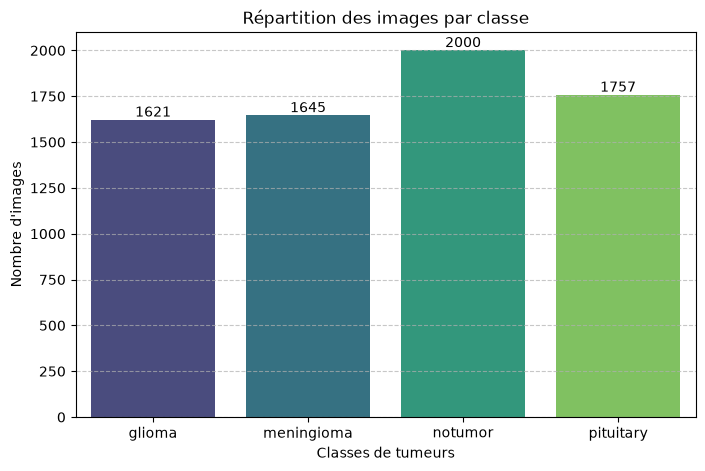

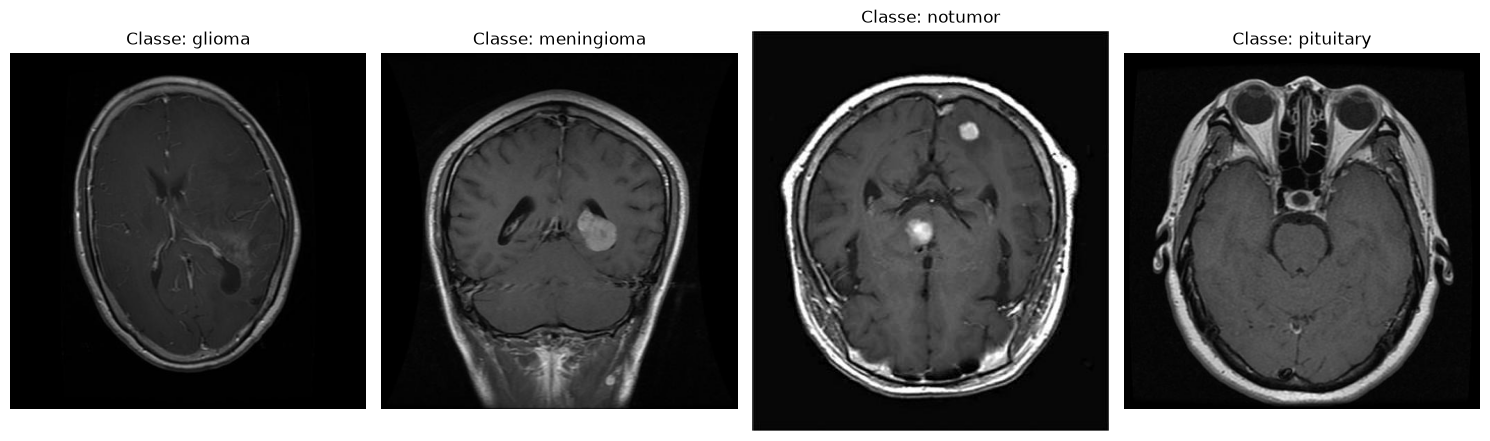

--- Répartition des jeux de données ---
Train (70%)      : 4916 images
Validation (15%) : 1053 images
Test (15%)       : 1054 images
Total            : 7023 images


In [4]:
# --- 1. Création d'un DataFrame pour faciliter l'exploration ---
df = pd.DataFrame({
    'chemin': images_valides,
    'label': labels
})

classes = df['label'].unique().tolist()
print(f"Classes détectées ({len(classes)}) : {classes}")

# --- 2. Countplot de la distribution des classes ---

plt.figure(figsize=(8, 5))

# Correction : associer hue à x et désactiver la légende
ax = sns.countplot(data=df, x='label', hue='label', palette='viridis', legend=False)

# Affichage automatique des valeurs sur chaque barre
for container in ax.containers:
    ax.bar_label(container)

plt.title("Répartition des images par classe")
plt.xlabel("Classes de tumeurs")
plt.ylabel("Nombre d'images")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# --- 3. Affichage d'un échantillon d'images pour chaque classe ---
fig, axes = plt.subplots(1, len(classes), figsize=(15, 5))

for i, classe in enumerate(classes):
    # Prendre une image au hasard de la classe actuelle
    chemin_sample = df[df['label'] == classe]['chemin'].sample(1, random_state=42).values[0]
    img = cv2.imread(chemin_sample)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # OpenCV lit en BGR, convertit en RGB
    
    axes[i].imshow(img)
    axes[i].set_title(f"Classe: {classe}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# --- 4. Séparation en Train (70%), Validation (15%) et Test (15%) ---
# Première séparation : 70% Train, 30% Reste (Val + Test)
train_df, reste_df = train_test_split(
    df, 
    test_size=0.30, 
    random_state=42, 
    stratify=df['label'] # Maintient la proportion des classes
)

# Deuxième séparation : On coupe les 30% restants en 2 parts égales (15% Val, 15% Test)
val_df, test_df = train_test_split(
    reste_df, 
    test_size=0.50, 
    random_state=42, 
    stratify=reste_df['label']
)

# --- 5. Bilan du découpage ---
print("--- Répartition des jeux de données ---")
print(f"Train (70%)      : {len(train_df)} images")
print(f"Validation (15%) : {len(val_df)} images")
print(f"Test (15%)       : {len(test_df)} images")
print(f"Total            : {len(train_df) + len(val_df) + len(test_df)} images")

In [9]:
# --- 1. Définition du dossier de destination ---
base_processed_dir = "./Data/processed"

# Subdivisions à créer : train, val, test
splits = {
    'train': train_df,
    'val': val_df,
    'test': test_df
}

print("Début de la sauvegarde des images sur le disque...")

# --- 2. Parcours de chaque sous-ensemble (train, val, test) ---
for split_name, df_split in splits.items():
    print(f"\nTraitement du dossier : {split_name}...")
    
    # Parcourt chaque ligne du DataFrame (chemin de l'image d'origine et sa classe)
    for index, row in df_split.iterrows():
        chemin_origine = row['chemin']
        classe = row['label']
        nom_fichier = os.path.basename(chemin_origine)
        
        # Création du dossier cible pour la classe (ex: ./Data/processed/train/glioma)
        dossier_cible = os.path.join(base_processed_dir, split_name, classe)
        os.makedirs(dossier_cible, exist_ok=True)
        
        # Chemin complet de l'image sauvegardée
        chemin_destination = os.path.join(dossier_cible, nom_fichier)
        
        # --- 3. Lecture et enregistrement du fichier image ---
        # On lit l'image depuis son chemin source avec OpenCV
        img = cv2.imread(chemin_origine)
        
        if img is not None:
            # On réécrit l'image physique dans son nouveau dossier
            cv2.imwrite(chemin_destination, img)
        else:
            print(f"Erreur de lecture pour l'image : {chemin_origine}")

print("\n--- Sauvegarde terminée avec succès ! ---")

Début de la sauvegarde des images sur le disque...

Traitement du dossier : train...

Traitement du dossier : val...

Traitement du dossier : test...

--- Sauvegarde terminée avec succès ! ---


In [8]:
# --- 1. Paramètres globaux ---
IMG_SIZE = (299, 299)  # Dimension exacte requise par GoogLeNet / InceptionV3
BATCH_SIZE = 32        # Nombre d'images traitées par lot

# --- 2. Construction de la couche d'augmentation de données ---
# S'applique UNIQUEMENT sur l'ensemble d'entraînement
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.15),
    RandomZoom(0.1),
    GaussianNoise(0.05) # Ajout de bruit gaussien
], name="data_augmentation")


# --- 3. Fonction d'extraction et de prétraitement d'une image ---

def charger_et_pretraiter_image(chemin, label_index, est_train=False):
    # Lecture du fichier image sur le disque
    img_bytes = tf.io.read_file(chemin)
    # Décodage de l'image (PNG, JPG, BMP, JPEG) en tensor RGB (3 canaux)
    img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
    # Redimensionnement vers la taille GoogLeNet (299x299)
    img = tf.image.resize(img, IMG_SIZE)

    # Normalisation propre à GoogLeNet / InceptionV3 (ramène les pixels entre -1 et 1)
    img = preprocess_input(img)

    # Application de l'augmentation uniquement si demandé (Train)
    if est_train:
        img = data_augmentation(img)

    return img, label_index

# --- 4. Encodage des labels textuels en nombres (0, 1, 2, 3) ---
encoder = LabelEncoder()
train_labels_encoded = encoder.fit_transform(train_df['label'])
val_labels_encoded = encoder.transform(val_df['label'])
test_labels_encoded = encoder.transform(test_df['label'])


# --- 5. Construction des Data Pipelines TensorFlow optimisés ---
def creer_pipeline(df_paths, labels_encoded, est_train = False):
    # Création du dataset à partir des chemins et des labels
    dataset = tf.data.Dataset.from_tensor_slices((df_paths.values, labels_encoded))

    if est_train:
        # Mélange des données pour le jeu d'entraînement
        dataset = dataset.map(lambda x, y: charger_et_pretraiter_image(x, y, est_train=True),
                              num_parallel_calls=tf.data.AUTOTUNE)

    else:
        # Préparation simple sans augmentation pour Validation et Test
        dataset = dataset.map(lambda x,y: charger_et_pretraiter_image(x, y, est_train= False),
                              num_parallel_calls=tf.data.AUTOTUNE)

    # Groupement par lots (batches) et préchargement GPU (prefetch) pour des performances maximales
    dataset = dataset.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
    return dataset


# Génération des 3 pipelines
train_ds =creer_pipeline(train_df["chemin"], train_labels_encoded, est_train=True)
val_ds =creer_pipeline(val_df["chemin"], val_labels_encoded, est_train=False)
test_ds =creer_pipeline(test_df["chemin"], test_labels_encoded, est_train=False)

print("Pipelines d'entraînement, de validation et de test créés avec succès !")


Pipelines d'entraînement, de validation et de test créés avec succès !


In [15]:
# ==============================================================================
# ÉTAPE 1.4.1 : Construction du modèle GoogLeNet (InceptionV3) en Sequential
# ==============================================================================

# --- 1. Chargement de l'architecture de base (Backbone) ---
# InceptionV3 : Le réseau pré-entraîné GoogLeNet
# weights='imagenet' : Charge les poids entraînés sur la base ImageNet (1.4 million d'images)
# include_top=False : Supprime la dernière couche de classification d'origine (1000 classes)
# input_shape=(299, 299, 3) : Spécifie la taille requise des images (299x299 pixels, 3 canaux RGB)
base_model = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(299, 299, 3)
)

# --- 2. Gel du backbone (Feature Extraction) ---
# trainable = False : Empêche la modification des poids du réseau InceptionV3 pendant l'entraînement.
# Le modèle conserve ainsi ses compétences visuelles sans altérer ses filtres appris.
base_model.trainable = False

# --- 3. Assemblage des couches avec l'API Sequential ---
# On empile les couches une par une dans une liste simple :
model = Sequential([
    # Couche 1 : Le modèle InceptionV3 gelé qui extrait les caractéristiques visuelles de l'image IRM
    base_model,
    
    # Couche 2 : GlobalAveragePooling2D
    # Réduit la grille de sortie 3D (8x8x2048) en un vecteur 1D de 2048 éléments en calculant la moyenne.
    # Cela évite de créer trop de paramètres et prévient le surapprentissage.
    GlobalAveragePooling2D(name="avg_pool"),
    
    # Couche 3 : Dropout (30%)
    # Désactive aléatoirement 30% des connexions à chaque passe d'entraînement.
    # Force le réseau à apprendre des caractéristiques plus robustes et indépendantes.
    Dropout(0.3, name="dropout"),
    
    # Couche 4 : Dense (Couche de sortie)
    # 4 neurones : Un pour chaque classe de tumeur (glioma, meningioma, notumor, pituitary).
    # activation='softmax' : Convertit les sorties en probabilités comprises entre 0 et 1 (somme = 100%).
    Dense(4, activation='softmax', name="output_layer")
], name="GoogLeNet_Brain_Tumor_Classifier")

# --- 4. Compilation du modèle ---
# Adam(0.001) : Optimiseur adaptatif avec un taux d'apprentissage standard de 0.001
# loss='sparse_categorical_crossentropy' : Fonction de perte adaptée lorsque les labels sont des entiers (0, 1, 2, 3)
# metrics=['accuracy'] : Suit le pourcentage global de bonnes prédictions
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# --- 5. Affichage de la structure du modèle ---
# Affiche la liste des couches, les dimensions de sortie et le nombre de paramètres
model.summary()

Model: "GoogLeNet_Brain_Tumor_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool                        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
# ==============================================================================
# ÉTAPE 1.4.2 : Configuration des Callbacks et Lancement de l'Entraînement
# ==============================================================================

# --- 1. Définition des hyperparamètres ---
EPOCHS = 15  # Nombre maximal de passages complets sur le dataset

# --- 2. Création du dossier pour sauvegarder le modèle ---
models_dir = "./models"
os.makedirs(models_dir, exist_ok=True)
checkpoint_path = os.path.join(models_dir, "best_googlenet_feature_extraction.keras")
csv_log_path = os.path.join(models_dir, "training_history_fe.csv")

# --- 3. Définition des Callbacks ---

# Callback 1 : Sauvegarde automatique du meilleur modèle
checkpoint_cb = ModelCheckpoint(
    filepath=checkpoint_path,        # Chemin du fichier de sauvegarde
    monitor='val_loss',               # Surveille la perte sur le jeu de validation
    save_best_only=True,             # Conserve uniquement la version ayant la meilleure val_loss
    mode='min',                       # Cherche à minimiser la perte (val_loss la plus basse)
    verbose=1                         # Affiche un message à chaque sauvegarde
)

# Callback 2 : Réduit le Learning Rate si val_loss stagne pendant 2 époques
reduce_lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,          # Divise le learning rate par 5 (0.001 -> 0.0002)
    patience=2,          # Attend 2 époques de stagnation avant de réduire
    min_lr=1e-6,         # Taux d'apprentissage minimum autorisé
    verbose=1
)

# Callback 3 : Arrêt précoce pour éviter le surapprentissage
early_stopping_cb = EarlyStopping(
    monitor='val_loss',               # Surveille la perte en validation
    patience=3,                       # S'arrête si val_loss ne s'améliore pas pendant 3 époques de suite
    restore_best_weights=True,        # Restaure automatiquement les meilleurs poids à la fin
    verbose=1
)

# Callback 4 : Sauvegarde l'historique dans un fichier CSV
csv_logger_cb = CSVLogger(
    filename=csv_log_path,
    separator=',',
    append=False
)

# --- 4. Lancement de l'entraînement (fit) ---
print("Début de l'entraînement en Feature Extraction...")

history = model.fit(
    train_ds,                         # Pipeline d'entraînement (contient déjà BATCH_SIZE=32)
    validation_data=val_ds,           # Pipeline de validation
    epochs=EPOCHS,                     # Nombre d'époques maximum
    callbacks=[checkpoint_cb, early_stopping_cb]  # Intégration des callbacks
)

print("\n--- Entraînement terminé avec succès ! ---")

In [ ]:
# --- 1. Création du dossier pour sauvegarder les graphiques GitHub ---
reports_dir = "./reports/figures"
os.makedirs(reports_dir, exist_ok=True)

# ==============================================================================
# A. TRACÉ ET SAUVEGARDE DES COURBES D'APPRENTISSAGE (Loss & Accuracy)
# ==============================================================================
plt.figure(figsize=(14, 5))

# Graphique 1 : Accuracy (Train vs Validation)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', linewidth=2)
plt.title('Évolution de la Précision (Accuracy)', fontsize=14)
plt.xlabel('Époques', fontsize=12)
plt.ylabel('Précision', fontsize=12)
plt.legend()
plt.grid(True)

# Graphique 2 : Loss (Train vs Validation)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='blue', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', color='orange', linewidth=2)
plt.title('Évolution de la Perte (Loss)', fontsize=14)
plt.xlabel('Époques', fontsize=12)
plt.ylabel('Perte', fontsize=12)
plt.legend()
plt.grid(True)

plt.tight_layout()
# Sauvegarde en haute résolution pour le README GitHub
curves_path = os.path.join(reports_dir, "fe_learning_curves.png")
plt.savefig(curves_path, dpi=300)
plt.show()
print(f"Courbes enregistrées dans : {curves_path}")


# ==============================================================================
# B. ÉVALUATION SUR LE JEU DE TEST ET MATRICE DE CONFUSION
# ==============================================================================

# 1. Chargement du meilleur modèle sauvegardé pendant l'entraînement
print("\nChargement du meilleur modèle sauvegardé...")
best_model = tf.keras.models.load_model("./models/best_googlenet_feature_extraction.keras")

# 2. Évaluation rapide sur le dataset de test
test_loss, test_acc = best_model.evaluate(test_ds)
print(f"\n---> Résultat global sur le jeu de Test : Accuracy = {test_acc*100:.2f}% | Loss = {test_loss:.4f}")

# 3. Récupération des vraies étiquettes et des prédictions
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

# Noms des 4 classes de tumeurs dans l'ordre de l'encoder
class_names = list(encoder.classes_)

# 4. Affichage du Rapport de Classification complet (Precision, Recall, F1-Score)
print("\n--- RAPPORT DE CLASSIFICATION DETAILLE ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 5. Tracé et Sauvegarde de la Matrice de Confusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de Confusion - Feature Extraction', fontsize=14)
plt.xlabel('Classe Prédite', fontsize=12)
plt.ylabel('Vraie Classe', fontsize=12)

cm_path = os.path.join(reports_dir, "fe_confusion_matrix.png")
plt.savefig(cm_path, dpi=300)
plt.show()
print(f"Matrice de confusion enregistrée dans : {cm_path}")